# Exploratory Data Analysis — EdTech Learning Outcomes

## Project Objective

The objective of this exploratory analysis is to understand student engagement, academic performance, retention, and withdrawal patterns using the cleaned OULAD datasets.

The analysis will investigate:

- Student demographic and academic characteristics
- Distribution of final outcomes
- Student registration and withdrawal behavior
- VLE engagement patterns
- Assessment performance
- Relationship between engagement and academic outcomes
- Factors associated with student withdrawal
- Differences in learning behavior across student groups

## Key Business Questions

1. What proportion of students pass, fail, achieve distinction, or withdraw?
2. Which student characteristics are associated with different outcomes?
3. How does student engagement vary across courses and presentations?
4. Are students who withdraw less engaged with the VLE?
5. Does early engagement relate to final academic outcomes?
6. How does assessment performance differ between successful and withdrawn students?
7. Which learner groups appear to be at higher risk of withdrawal?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [3]:
processed_path = "../data/processed"

In [8]:
student_info = pd.read_csv(
    os.path.join(processed_path, "student_info_cleaned.csv")
)

student_registration = pd.read_csv(
    os.path.join(processed_path, "student_registration_cleaned.csv")
)

student_vle = pd.read_csv(
    os.path.join(processed_path, "student_vle_cleaned.csv")
)

vle = pd.read_csv(
    os.path.join(processed_path, "vle_cleaned.csv")
)

assessments = pd.read_csv(
    os.path.join(processed_path, "assessments_cleaned.csv")
)

student_assessment = pd.read_csv(
    os.path.join(processed_path, "student_assessment_cleaned.csv")
)


In [10]:
datasets = {
    "Student_Info" : student_info,
    "Registration" : student_registration,
    "VLE Activity" : student_vle,
    "VLE Metadata" : vle,
    "Assessments" : assessments,
    "Student Assessment" : student_assessment
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("=" * 50)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Student_Info
Rows: 32593
Columns: 12

Registration
Rows: 32593
Columns: 5

VLE Activity
Rows: 9868110
Columns: 6

VLE Metadata
Rows: 6364
Columns: 6

Assessments
Rows: 206
Columns: 6

Student Assessment
Rows: 173912
Columns: 5


In [11]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [13]:
student_info.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
code_module,32593,7,BBB,7909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
code_presentation,32593,4,2014J,11260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_student,32593.0,NaN,NaN,NaN,706687.669131,549167.313855,3733.0,508573.0,590310.0,644453.0,2716795.0
gender,32593,2,M,17875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,32593,13,Scotland,3446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
highest_education,32593,5,A Level or Equivalent,14045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imd_band,32593,11,20-30%,3654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_band,32593,3,0-35,22944,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_of_prev_attempts,32593.0,NaN,NaN,NaN,0.163225,0.479758,0.0,0.0,0.0,0.0,6.0
studied_credits,32593.0,NaN,NaN,NaN,79.758691,41.0719,30.0,60.0,60.0,120.0,655.0


In [14]:
student_info["id_student"].nunique()

28785

In [15]:
student_info["id_student"].value_counts().describe()

count    28785.000000
mean         1.132291
std          0.367915
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: count, dtype: float64

In [16]:
outcome_counts = student_info["final_result"].value_counts()

outcome_counts

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [17]:
outcome_percentage = (
    student_info["final_result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

outcome_percentage

final_result
Pass           37.93
Withdrawn      31.16
Fail           21.64
Distinction     9.28
Name: proportion, dtype: float64

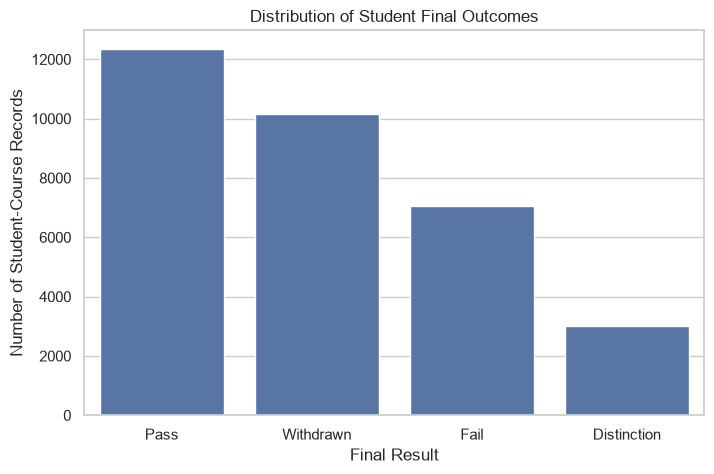

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=student_info,
    x="final_result",
    order=student_info["final_result"].value_counts().index
)
plt.title("Distribution of Student Final Outcomes")
plt.xlabel("Final Result")
plt.ylabel("Number of Student-Course Records")

plt.show()

In [19]:
student_info["dropout"] = (
    student_info["final_result"] == "Withdrawn"
).astype(int)

In [20]:
student_info["dropout"].value_counts()

dropout
0    22437
1    10156
Name: count, dtype: int64

In [21]:
student_info["dropout"].value_counts(normalize=True).mul(100).round(2)

dropout
0    68.84
1    31.16
Name: proportion, dtype: float64

In [22]:
gender_outcome = pd.crosstab(
    student_info["gender"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

gender_outcome

final_result,Distinction,Fail,Pass,Withdrawn
gender,,,,
F,9.47,21.08,38.97,30.48
M,9.12,22.09,37.07,31.72


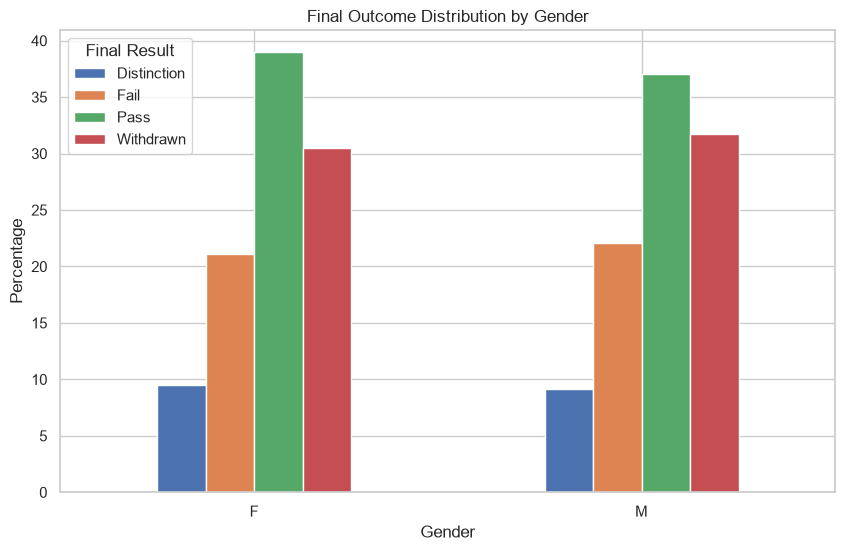

In [23]:
gender_outcome.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Final Outcome Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Final Result")

plt.show()

In [24]:
education_outcome = pd.crosstab(
    student_info["highest_education"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

education_outcome

final_result,Distinction,Fail,Pass,Withdrawn
highest_education,,,,
A Level or Equivalent,10.65,19.27,41.38,28.69
HE Qualification,14.74,16.70,41.44,27.12
Lower Than A Level,5.53,26.04,33.33,35.11
No Formal quals,4.61,27.38,25.07,42.94
Post Graduate Qualification,28.12,10.86,37.38,23.64


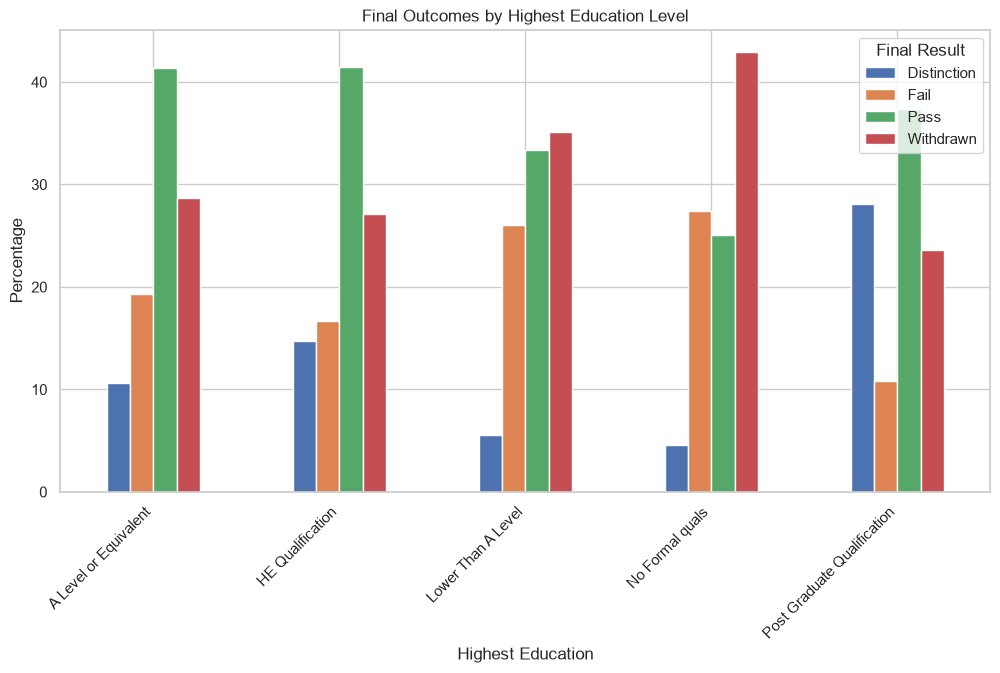

In [25]:
education_outcome.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Final Outcomes by Highest Education Level")
plt.xlabel("Highest Education")
plt.ylabel("Percentage")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Final Result")

plt.show()

In [26]:
age_outcome = pd.crosstab(
    student_info["age_band"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

age_outcome

final_result,Distinction,Fail,Pass,Withdrawn
age_band,,,,
0-35,8.12,22.80,36.91,32.17
35-55,11.87,19.00,40.28,28.85
55<=,18.98,13.43,42.59,25.00


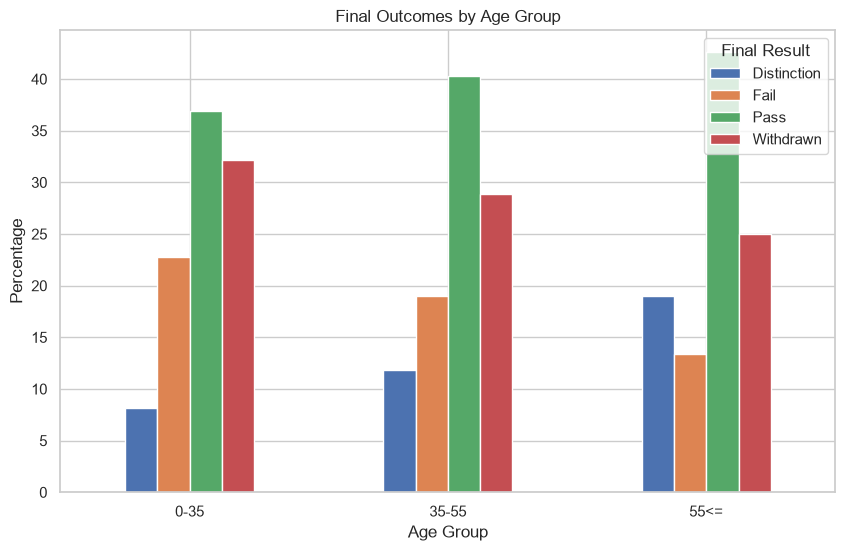

In [27]:
age_outcome.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Outcomes by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Final Result")

plt.show()

In [28]:
attempt_outcome = pd.crosstab(
    student_info["num_of_prev_attempts"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

attempt_outcome

final_result,Distinction,Fail,Pass,Withdrawn
num_of_prev_attempts,,,,
0,10.05,20.16,39.22,30.56
1,4.33,30.59,30.22,34.86
2,3.26,34.96,25.19,36.59
3,0.70,40.14,21.83,37.32
4,0.00,30.77,33.33,35.90
5,0.00,46.15,15.38,38.46
6,25.00,25.00,0.00,50.00


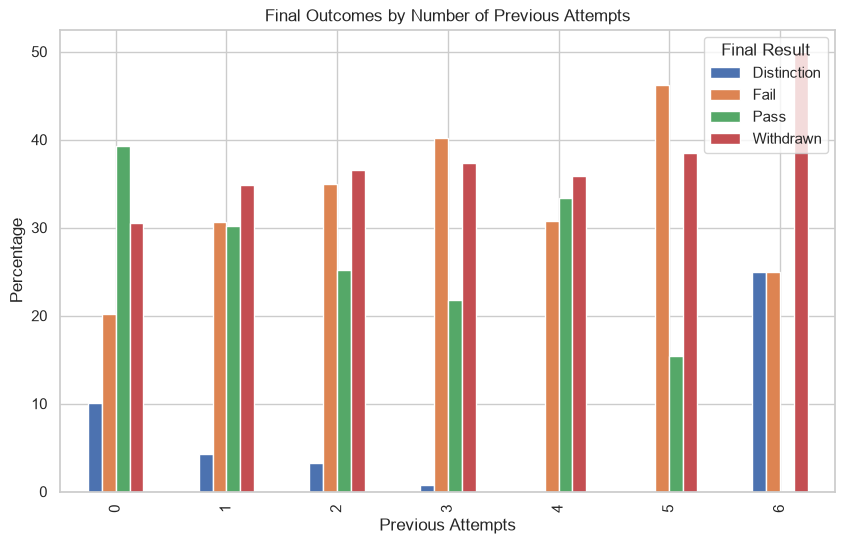

In [29]:
attempt_outcome.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Outcomes by Number of Previous Attempts")
plt.xlabel("Previous Attempts")
plt.ylabel("Percentage")
plt.legend(title="Final Result")

plt.show()

In [30]:
student_info.groupby("final_result")["studied_credits"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
final_result,,,,,
Distinction,3024,71.76,60.0,30,330
Fail,7052,76.09,60.0,30,360
Pass,12361,74.22,60.0,30,630
Withdrawn,10156,91.43,60.0,30,655


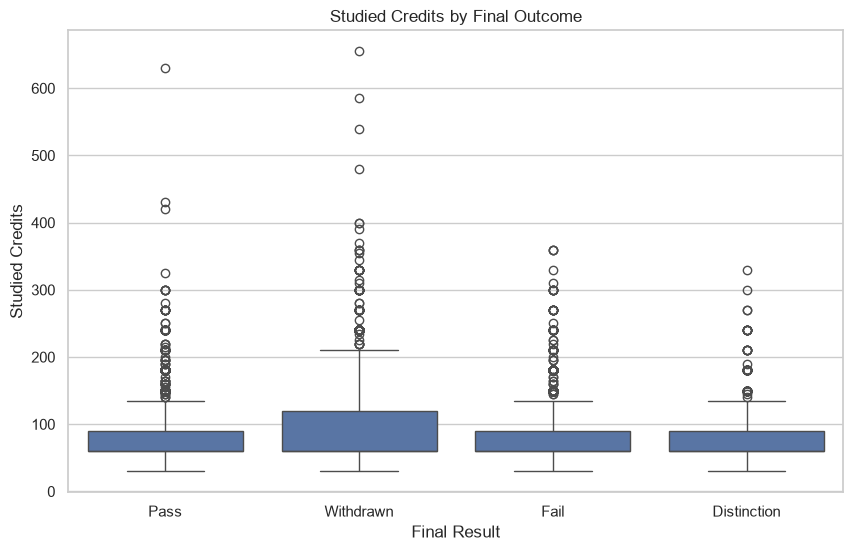

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=student_info,
    x="final_result",
    y="studied_credits"
)

plt.title("Studied Credits by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Studied Credits")

plt.show()

In [32]:
region_outcome = pd.crosstab(
    student_info["region"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

region_outcome.sort_values(
    "Withdrawn",
    ascending=False
)

final_result,Distinction,Fail,Pass,Withdrawn
region,,,,
North Western Region,7.33,24.23,32.86,35.58
West Midlands Region,7.05,21.34,36.25,35.36
East Midlands Region,8.46,19.53,37.25,34.76
London Region,8.18,23.13,34.17,34.51
Yorkshire Region,8.23,22.38,36.64,32.75
North Region,12.62,17.94,37.90,31.54
South West Region,10.84,19.09,38.96,31.12
South East Region,11.56,17.76,39.93,30.74
East Anglian Region,9.79,20.90,39.19,30.12


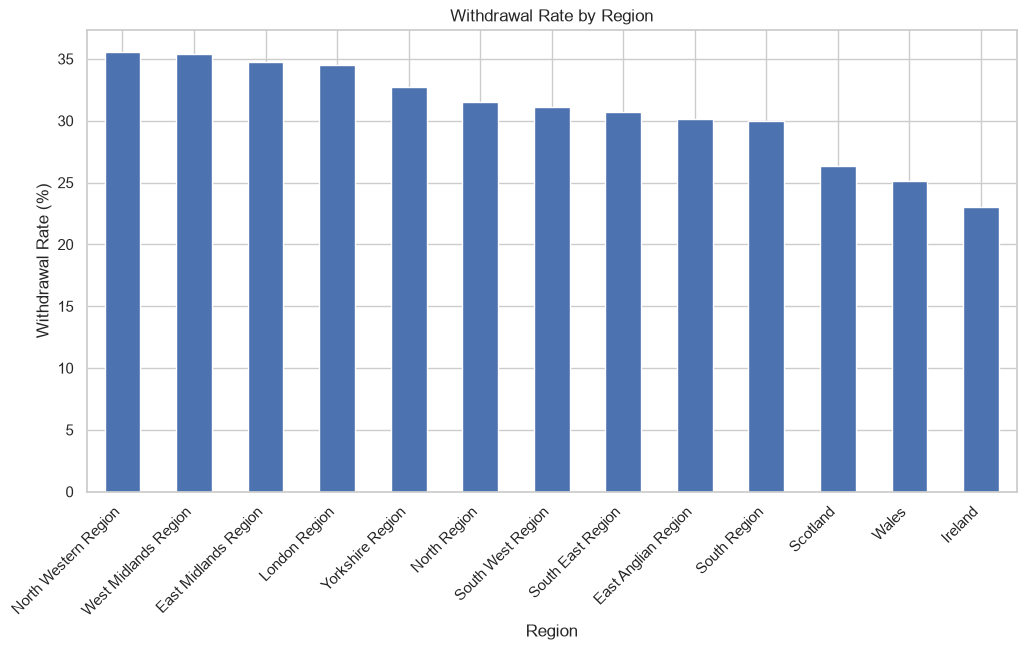

In [33]:
withdrawal_by_region = (
    student_info
    .groupby("region")["dropout"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

withdrawal_by_region.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Withdrawal Rate by Region")
plt.xlabel("Region")
plt.ylabel("Withdrawal Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.show()

In [34]:
disability_outcome = pd.crosstab(
    student_info["disability"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

disability_outcome

final_result,Distinction,Fail,Pass,Withdrawn
disability,,,,
N,9.52,21.54,38.66,30.28
Y,7.05,22.50,31.10,39.35


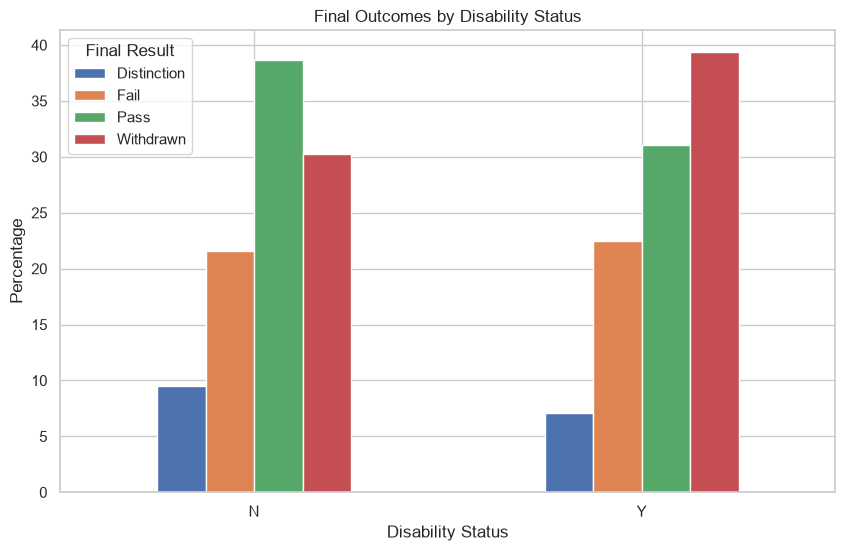

In [35]:
disability_outcome.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Outcomes by Disability Status")
plt.xlabel("Disability Status")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Final Result")

plt.show()

In [36]:
student_info["imd_band"].value_counts(dropna=False)

imd_band
20-30%     3654
30-40%     3539
10-20      3516
0-10%      3311
40-50%     3256
50-60%     3124
60-70%     2905
70-80%     2879
80-90%     2762
90-100%    2536
?          1111
Name: count, dtype: int64

In [37]:
imd_outcome = pd.crosstab(
    student_info["imd_band"],
    student_info["final_result"],
    normalize="index"
).mul(100).round(2)

imd_outcome

final_result,Distinction,Fail,Pass,Withdrawn
imd_band,,,,
0-10%,5.07,27.67,30.08,37.18
10-20,5.43,25.94,33.19,35.44
20-30%,7.20,23.10,33.55,36.15
30-40%,8.90,22.15,38.01,30.94
40-50%,9.00,21.41,37.59,32.00
50-60%,9.51,22.44,39.28,28.78
60-70%,10.29,18.52,41.62,29.57
70-80%,10.87,20.81,40.64,27.68
80-90%,11.88,17.92,42.18,28.02


In [45]:
student_engagement = (
    student_vle
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )
    .agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique")
    )
    .reset_index()
)

student_engagement["avg_clicks_per_active_day"] = (
    student_engagement["total_clicks"] /
    student_engagement["active_days"]
)

student_engagement.head()

,id_student,code_module,code_presentation,total_clicks,active_days,avg_clicks_per_active_day
0,6516,AAA,2014J,2715,159,17.075472
1,8462,DDD,2013J,634,56,11.321429
2,8462,DDD,2014J,9,1,9.000000
3,11391,AAA,2013J,922,40,23.050000
4,23629,BBB,2013B,153,16,9.562500


In [39]:
student_engagement["avg_clicks_per_active_day"] = (
    student_engagement["total_clicks"] /
    student_engagement["active_days"]
)

In [40]:
student_engagement.describe()

,id_student,total_clicks,active_days,avg_clicks_per_active_day
count,2.607400e+04,26074.000000,26074.000000,26074.000000
mean,7.087453e+05,1470.547787,20.228580,53.796910
std,5.529544e+05,1885.362646,12.832971,39.967220
min,6.516000e+03,1.000000,1.000000,1.000000
25%,5.067170e+05,282.000000,11.000000,24.534615
50%,5.901150e+05,791.000000,17.000000,45.137147
75%,6.459182e+05,1955.750000,27.000000,73.706958
max,2.698588e+06,27922.000000,109.000000,457.000000


In [46]:
engagement_outcome = student_info.merge(
    student_engagement,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

In [42]:
engagement_outcome[
    [
        "id_student",
        "final_result",
        "dropout",
        "total_clicks",
        "active_days",
        "avg_clicks_per_active_day"
    ]
].head()

,id_student,final_result,dropout,total_clicks,active_days,avg_clicks_per_active_day
0,11391,Pass,0,922.0,24.0,38.416667
1,28400,Pass,0,1409.0,21.0,67.095238
2,30268,Withdrawn,1,260.0,13.0,20.000000
3,31604,Pass,0,2007.0,20.0,100.350000
4,32885,Pass,0,1012.0,18.0,56.222222


In [49]:
engagement_by_outcome = (
    engagement_outcome
    .groupby("final_result")[
        [
            "total_clicks",
            "active_days",
            "avg_clicks_per_active_day"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

engagement_by_outcome

total_clicks         active_days         \
                     mean  median        mean median   
final_result                                           
Distinction       2574.43  1819.0      110.04  103.0   
Fail               631.78   305.5       33.18   22.0   
Pass              1862.00  1294.0       87.04   78.0   
Withdrawn          303.91    85.0       16.29    7.0   

             avg_clicks_per_active_day         
                                  mean median  
final_result                                   
Distinction                      21.11  18.58  
Fail                             15.75  13.40  
Pass                             19.76  17.15  
Withdrawn                        11.67   9.75

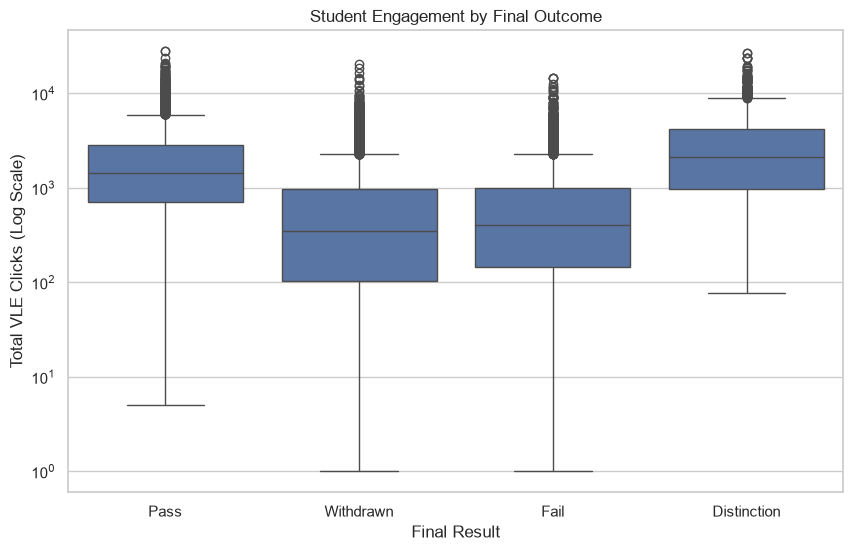

In [44]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=engagement_outcome,
    x="final_result",
    y="total_clicks"
)

plt.yscale("log")

plt.title("Student Engagement by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Total VLE Clicks (Log Scale)")

plt.show()

In [47]:
engagement_columns = [
    "total_clicks",
    "active_days",
    "avg_clicks_per_active_day"
]

engagement_outcome[engagement_columns] = (
    engagement_outcome[engagement_columns]
    .fillna(0)
)


In [48]:
engagement_outcome[
    engagement_columns
].isnull().sum()

total_clicks                 0
active_days                  0
avg_clicks_per_active_day    0
dtype: int64

In [50]:
engagement_outcome[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "final_result",
        "dropout",
        "total_clicks",
        "active_days",
        "avg_clicks_per_active_day"
    ]
].head()

,id_student,code_module,code_presentation,final_result,dropout,total_clicks,active_days,avg_clicks_per_active_day
0,11391,AAA,2013J,Pass,0,922.0,40.0,23.050000
1,28400,AAA,2013J,Pass,0,1409.0,80.0,17.612500
2,30268,AAA,2013J,Withdrawn,1,260.0,12.0,21.666667
3,31604,AAA,2013J,Pass,0,2007.0,123.0,16.317073
4,32885,AAA,2013J,Pass,0,1012.0,70.0,14.457143


In [51]:
engagement_columns = [
    "total_clicks",
    "active_days",
    "avg_clicks_per_active_day"
]

engagement_outcome[engagement_columns] = (
    engagement_outcome[engagement_columns]
    .fillna(0)
)

In [52]:
engagement_outcome[engagement_columns].isnull().sum()

total_clicks                 0
active_days                  0
avg_clicks_per_active_day    0
dtype: int64

In [53]:
engagement_by_outcome = (
    engagement_outcome
    .groupby("final_result")[
        [
            "total_clicks",
            "active_days",
            "avg_clicks_per_active_day"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

engagement_by_outcome

total_clicks         active_days         \
                     mean  median        mean median   
final_result                                           
Distinction       2574.43  1819.0      110.04  103.0   
Fail               631.78   305.5       33.18   22.0   
Pass              1862.00  1294.0       87.04   78.0   
Withdrawn          303.91    85.0       16.29    7.0   

             avg_clicks_per_active_day         
                                  mean median  
final_result                                   
Distinction                      21.11  18.58  
Fail                             15.75  13.40  
Pass                             19.76  17.15  
Withdrawn                        11.67   9.75

In [57]:
engagement_summary = (
    engagement_outcome
    .groupby("final_result")
    .agg(
        student_course_records=("id_student", "count"),
        avg_total_clicks=("total_clicks", "mean"),
        median_total_clicks=("total_clicks", "median"),
        avg_active_days=("active_days", "mean"),
        median_active_days=("active_days", "median"),
        avg_clicks_per_active_day=("avg_clicks_per_active_day", "mean"),
        median_clicks_per_active_day=("avg_clicks_per_active_day", "median")
    )
    .round(2)
    .sort_values("avg_total_clicks", ascending=False)
)

engagement_summary

,student_course_records,avg_total_clicks,median_total_clicks,avg_active_days,median_active_days,avg_clicks_per_active_day,median_clicks_per_active_day
final_result,,,,,,,
Distinction,3024,2574.43,1819.0,110.04,103.0,21.11,18.58
Pass,12361,1862.00,1294.0,87.04,78.0,19.76,17.15
Fail,7052,631.78,305.5,33.18,22.0,15.75,13.40
Withdrawn,10156,303.91,85.0,16.29,7.0,11.67,9.75


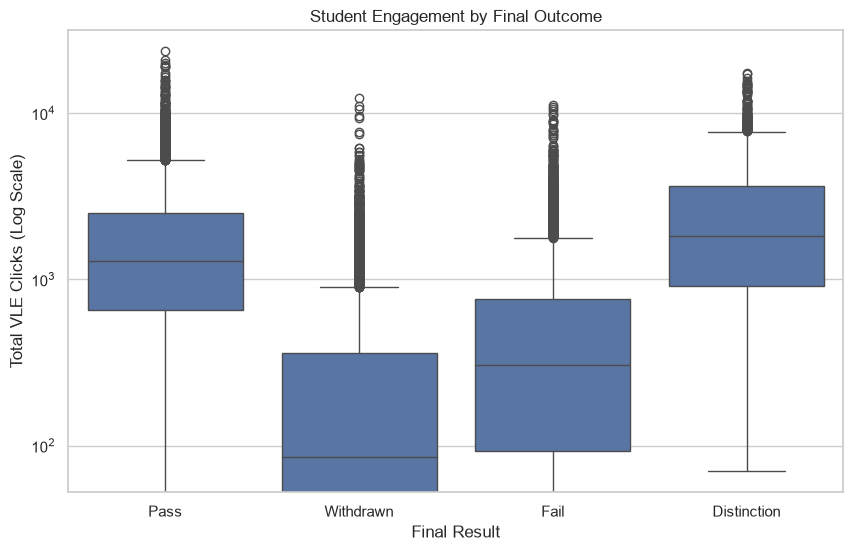

In [58]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=engagement_outcome,
    x="final_result",
    y="total_clicks"
)

plt.yscale("log")

plt.title("Student Engagement by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Total VLE Clicks (Log Scale)")

plt.show()